# Dự Án Học Tăng Cường: Pac-Man với Approximate Q-Learning

Dự án này được xây dựng dựa trên cấu trúc chuẩn **RL-Glue** của chuỗi bài tập **Assignment 1 – 3**, áp dụng phương pháp **Approximate Q-Learning (Học Q xấp xỉ tuyến tính)** vào trò chơi kinh điển **Pac-Man** với đầy đủ bảng luật phổ biến.

## 1. Bảng Luật Chuẩn Của Trò Chơi Pac-Man (Classic Arcade Rules)
- **Bản đồ mê cung (21×19)**: Tường (`#`), 180 hạt điểm thường (`.`), 4 viên năng lượng lớn — *Power Pellets / Energizers* (`o`), cổng nhà ma (`-`), đường hầm xuyên biên trái-phải (*warp tunnel*), vị trí xuất phát của Pac-Man (`P`) và 4 hồn ma (`G`).
- **4 Hồn Ma (Ghosts) với chiến thuật săn đuổi riêng biệt**:
  1. **Blinky (Đỏ)**: Truy đuổi trực tiếp vị trí hiện tại của Pac-Man.
  2. **Pinky (Hồng)**: Đón đầu vị trí cách Pac-Man 4 ô theo hướng di chuyển.
  3. **Inky (Xanh lơ)**: Phối hợp cùng vị trí của Blinky để kẹp góc.
  4. **Clyde (Cam)**: Đuổi theo khi ở xa (> 6 ô), rút lui về góc dưới bên trái khi ở gần.
- **Hệ thống Phần thưởng (Reward Structure)**:
  - Ăn hạt thường (*Pellet*): **`+10`** điểm
  - Ăn viên năng lượng (*Power Pellet / Energizer*): **`+50`** điểm và chuyển tất cả hồn ma sang trạng thái **Hoảng sợ (*Scared*)** trong 40 bước.
  - Ăn hồn ma đang hoảng sợ (*Scared Ghost*): **`+200`** điểm (hồn ma bị đưa về nhà chờ hồi sinh).
  - Phạt mỗi bước thời gian (*Living Step Penalty*): **`-1`** điểm (khuyến khích dọn mê cung nhanh nhất có thể).
  - Va chạm với hồn ma thường (*Active Ghost*): **`-500`** điểm và kết thúc màn chơi (**GAME OVER**).
  - Ăn hết toàn bộ hạt trên bản đồ (*Stage Clear*): **`+500`** điểm và chiến thắng màn chơi (**WIN**).

---
## 2. Phương Pháp Approximate Q-Learning
Do không gian trạng thái của Pac-Man cực lớn (hơn $2^{180}$ trạng thái), ta xấp xỉ hàm giá trị hành động $Q(s, a)$ bằng tổ hợp tuyến tính của vector đặc trưng $\mathbf{f}(s, a) \in \mathbb{R}^9$ và vector trọng số $\mathbf{w} \in \mathbb{R}^9$:

$$Q(s, a) = \mathbf{w}^\top \mathbf{f}(s, a) = \sum_{i=1}^{9} w_i f_i(s, a)$$

Tại mỗi bước chuyển trạng thái $(s, a, R, s')$, sai số TD (*Temporal-Difference Error*) và quy tắc cập nhật trọng số là:

$$\delta = R + \gamma \max_{a' \in \text{Legal}(s')} Q(s', a') - Q(s, a)$$
$$\mathbf{w} \leftarrow \mathbf{w} + \alpha \, \delta \, \mathbf{f}(s, a)$$

In [1]:
# Import các thư viện chuẩn của khóa học (RL-Glue framework)
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from rl_glue import RLGlue
from agent import BaseAgent
from environment import BaseEnvironment
from pacman_env import PacmanEnvironment, ACTION_DELTAS, OPPOSITE_ACTION
from pacman_agent import PacmanFeatureExtractor, ApproximateQAgent
from mp4_writer import MP4Writer, PacmanRenderer

%matplotlib inline

## Phần 1: Kiểm tra Môi trường Pac-Man (`PacmanEnvironment`)
Môi trường kế thừa trực tiếp từ `BaseEnvironment` của `rl_glue`, cung cấp các phương thức chuẩn `env_init`, `env_start`, `env_step`, `env_cleanup`, và `env_message`.

In [2]:
env = PacmanEnvironment()
env.env_init({'seed': 101})
init_state = env.env_start()

print(f'Kích thước mê cung: {env.height} hàng x {env.width} cột')
print(f'Tổng số hạt thường ban đầu: {int(np.sum(init_state["pellets"]))}')
print(f'Tổng số viên năng lượng (Power Pellets): {int(np.sum(init_state["capsules"]))}')
print(f'Vị trí khởi đầu của Pacman: {init_state["pacman_pos"]}')
print('Danh sách 4 Ghosts:', [(g['name'], g['pos']) for g in init_state['ghosts']])

Kích thước mê cung: 21 hàng x 19 cột
Tổng số hạt thường ban đầu: 180
Tổng số viên năng lượng (Power Pellets): 4
Vị trí khởi đầu của Pacman: (15, 9)
Danh sách 4 Ghosts: [('Blinky', (7, 9)), ('Pinky', (9, 8)), ('Inky', (9, 9)), ('Clyde', (9, 10))]


## Phần 2: Trích xuất Đặc trưng (`PacmanFeatureExtractor`) & `ApproximateQAgent`
Vector đặc trưng $\mathbf{f}(s, a)$ gồm 9 đặc trưng trạng thái - hành động đã chuẩn hóa:
1. `bias`: Hệ số chệch hằng số $1.0$.
2. `eats_food`: $1.0$ nếu ô kế tiếp $(r', c')$ có hạt điểm và an toàn trước hồn ma.
3. `closest_food_inv`: Khoảng cách BFS chuẩn hóa trong mê cung tới hạt điểm gần nhất.
4. `active_ghost_dist1`: Số hồn ma nguy hiểm ở khoảng cách $\le 1$ bước từ $(r', c')$.
5. `active_ghost_dist2`: Số hồn ma nguy hiểm ở khoảng cách $2$ bước từ $(r', c')$.
6. `scared_ghost_hunt`: Ưu tiên săn đuổi hồn ma đang hoảng sợ (*Scared Ghost*) để nhận `+200` điểm.
7. `power_capsule_seek`: Ưu tiên tiến tới viên năng lượng (*Power Pellet*) khi hồn ma áp sát.
8. `trapped_danger`: Cảnh báo ngõ cụt bằng tìm kiếm đuổi-bắt 3 bước (*3-step pursuit-evasion lookahead*).
9. `stop_or_reverse`: Phạt đổi chiều liên tục tại chỗ khi không có ma ở gần.

In [3]:
# Kiểm tra trích xuất đặc trưng và cập nhật Q-learning của ApproximateQAgent
agent = ApproximateQAgent()
agent.agent_init({'seed': 101, 'alpha': 0.0035, 'gamma': 0.95, 'epsilon': 0.2})
first_action = agent.agent_start(init_state)
q_val, feats = agent.get_q_value(init_state, first_action)

print('Hành động đầu tiên được chọn:', first_action)
for fname, fval in zip(PacmanFeatureExtractor.FEATURE_NAMES, feats):
    print(f'  {fname:20s}: {fval:.4f}')

Hành động đầu tiên được chọn: 2
  bias                : 1.0000
  eats_food           : 1.0000
  closest_food_inv    : 1.0000
  active_ghost_dist1  : 0.0000
  active_ghost_dist2  : 0.0000
  scared_ghost_hunt   : 0.0000
  power_capsule_seek  : 0.3656
  trapped_danger      : 0.0000
  stop_or_reverse     : 1.0000


## Phần 3: Huấn luyện qua 250 Epochs và Xuất Video ở các Epoch 10, 50, 100, 200, 250
Quá trình huấn luyện sử dụng `RLGlue(PacmanEnvironment, ApproximateQAgent)` chạy xuyên suốt 250 Epochs và ghi hình trực tiếp các màn chơi ở **Epoch 10, 50, 100, 200, 250** vào file `Pacman_Approximate_QLearning.mp4`.

In [4]:
from train_and_record import run_training_and_record, RECORD_EPOCHS

# Nếu đã chạy huấn luyện thì tải kết quả để hiển thị nhanh; đặt FORCE_RETRAIN = True để chạy lại từ đầu
FORCE_RETRAIN = False
if FORCE_RETRAIN or not os.path.exists('Pacman_Approximate_QLearning.mp4') or not os.path.exists('pacman_training_results.npz'):
    run_training_and_record(
        num_epochs=250,
        video_path='Pacman_Approximate_QLearning.mp4',
        plot_path='learning_curve_pacman.png'
    )

data = np.load('pacman_training_results.npz', allow_pickle=True)
rewards = data['rewards']
steps = data['steps']
final_weights = data['final_weights']
feature_names = data['feature_names']

print('=== KẾT QUẢ TẠI CÁC MỐC EPOCH 10, 50, 100, 200, 250 ===')
for ep in [10, 50, 100, 200, 250]:
    print(f'Epoch {ep:3d} | Điểm số (Return): {rewards[ep-1]:7.1f} | Số bước (Steps): {steps[ep-1]:3d}')

print('\n=== TRỌNG SỐ HỌC ĐƯỢC SAU 250 EPOCHS ===')
for fname, w in zip(feature_names, final_weights):
    print(f'  {str(fname):20s}: {w:+.4f}')

=== KẾT QUẢ TẠI CÁC MỐC EPOCH 10, 50, 100, 200, 250 ===
Epoch  10 | Điểm số (Return):  -387.0 | Số bước (Steps):  17
Epoch  50 | Điểm số (Return):   707.0 | Số bước (Steps): 133
Epoch 100 | Điểm số (Return):  1791.0 | Số bước (Steps): 149
Epoch 200 | Điểm số (Return):  3170.0 | Số bước (Steps): 420
Epoch 250 | Điểm số (Return):  3391.0 | Số bước (Steps): 309

=== TRỌNG SỐ HỌC ĐƯỢC SAU 250 EPOCHS ===
  bias                : -0.0061
  eats_food           : +0.3550
  closest_food_inv    : +1.0689
  active_ghost_dist1  : -2.2663
  active_ghost_dist2  : -0.5214
  scared_ghost_hunt   : +1.9515
  power_capsule_seek  : +0.4765
  trapped_danger      : -0.8917
  stop_or_reverse     : -0.3541


## Phần 4: Biểu đồ Quá trình Học (Learning Curve qua 250 Epochs)

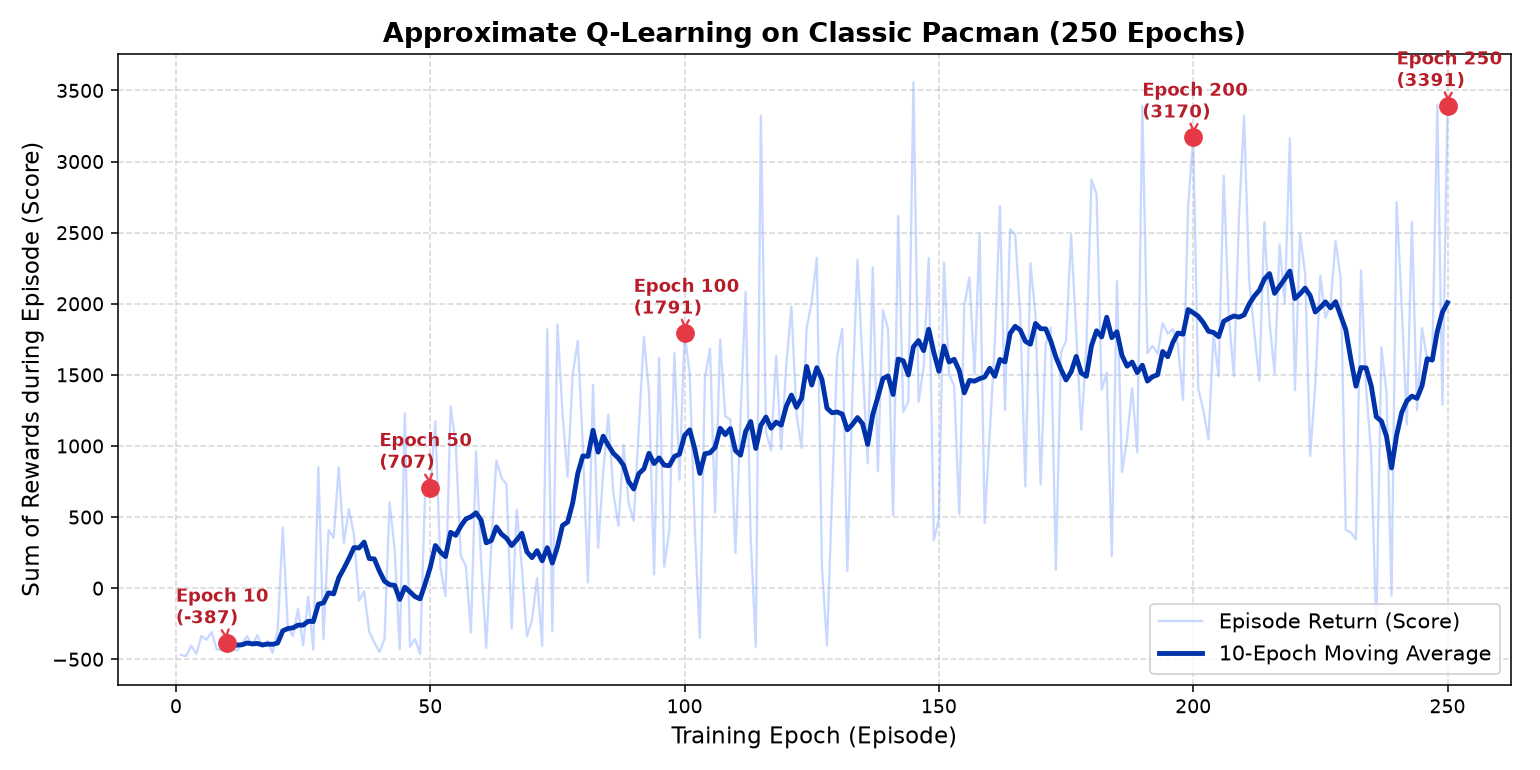

In [5]:
from IPython.display import Image as IPyImage, display
display(IPyImage(filename='learning_curve_pacman.png'))

## Phần 5: Video Kết quả Học Tăng Cường qua các Epoch 10, 50, 100, 200, 250
Tương tự cấu trúc hiển thị video của **Assignment 1**, chạy ô bên dưới để xem trực tiếp sự tiến bộ của tác tử Pac-Man qua các mốc **Epoch 10 → 50 → 100 → 200 → 250**:

In [6]:
%%HTML
<div align="center">
    <video width="608" height="720" controls autoplay loop>
        <source src="Pacman_Approximate_QLearning.mp4" type="video/mp4">
    </video>
</div>